## Final fitting of HPK Wlen data

nominal pinhole size is 2mm  
nominal wlens is 350-830nm

This notebook includes all the data:

9nm fwhm is negligible

1. Feb 24 2024 - HPK, all wlens
   1. cold - 160K
   2. old data
      1. veraData/HPK_IR_PDE_feb24_stat_error_only.csv - different processing we believe
      2. HPK_IR_PDE-Feb12_2024-Harry - has angles as well
   3. this was actually reprocessed with different QA data. new data to use is
      1. HPK_PDE_sept24.csv
   4. __only analyzing this data__
2. June/July 2024
   1. various temperatures (-80 to -40)
   2. veraData/angular_scans_VUV_feb2024/*
   3. for next analysis

calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


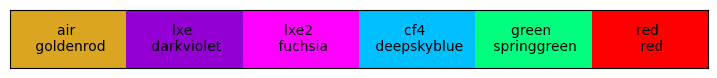

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d
import time

from scipy import optimize as opt
from scipy import stats as sps
import iminuit
from iminuit import Minuit

import json

import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PDEModel import PNJunction as PNJ

import FittingTools.FittingFunctions as FF
from FittingTools.FittingFunctions import *

import FittingTools.PDE_fittingTools as SS

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

rad2deg = 180/np.pi

---
---
## Parameters shared by everything

In [2]:
fixedPars_Boring = {"quantum": True, "smoothSigma": None, "dh":None, "window":True}

with open("input_systematics.json", 'r') as file:
    json_systematic = json.load(file)

FF1 = json_systematic["HPK_VUV4"]["input_systematics"]["FF"]
tOxide_values = json_systematic["HPK_VUV4"]["input_systematics"]["tOxide"]
ttGood = tOxide_values[0] # good thickness in nm
# vOffset = json_systematic["HPK_VUV4"]["Voffset"][1]
vOffset = 0.0

vH_wlenFit = json_systematic["HPK_VUV4"]["fit_parameters"]["Vh"][0]
vE_wlenFit = json_systematic["HPK_VUV4"]["fit_parameters"]["Ve"][0]

fitDict = json_systematic["HPK_VUV4"]["fit_parameters"]
fitVal_dict = {key: value[0] for key, value in fitDict.items()}
print(fitVal_dict)
fullDaaps_dict = {"FF":FF1, "tOxide":ttGood, **fitVal_dict, **fixedPars_Boring}

fullDaaps_dict_franta = {"FF":FF1, "tOxide":19.51, "Xpn": 1.0e3, "dp_star": 1.0e3, "dw_star": 1.0e3, "pe": 0.5, "ph": 0.5, "Ve": vE_wlenFit, "Vh": vH_wlenFit, "voltage": 1.0}

# fixedPars_physics = {"FF": FF1, "tOxide":ttGood, "Temperature": 160}
# fixedPars_parametrized = {"Ae":1.0, "Ah":1.0}

floatBounds_global_pickFrom = {'tOxide': (0.5, 50), 'dp_star': (0.1, 50), 'Xpn': (600, 5e3), 'dw_star': (5e3, 30e3),  "pe":(0,1.1), "ph":(0,1.1), "Ve":(0.5, 10), "Vh":(0.5, 30), "voltage":(0.5, 10)}

{'dp_star': 1.407, 'Xpn': 2318.8184, 'dw_star': 13299.2962, 'Ve': 1.7648, 'Vh': 16.1748}


-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


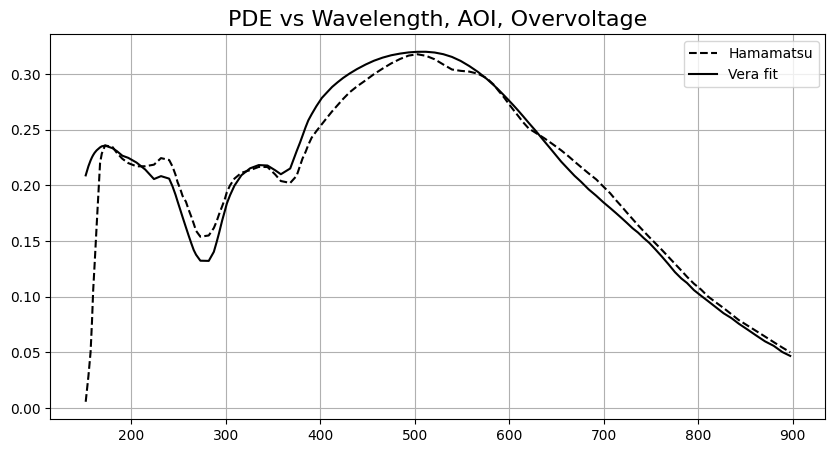

In [3]:
## Plot the data
fig, ax1 = plt.subplots(1, 1, sharex=True, figsize = (10, 5))

# hamamatsu curves
hamX, hamY = ODL.Load_Ham_data()
ax1.plot(hamX, hamY, label = "Hamamatsu", color = "black", linestyle = "--")

yFromData = FF.PDE_allArgs_wlen_parametrized(hamX, theta1=0, voltage = 4, **fullDaaps_dict)
ax1.plot(hamX, yFromData, label = "Vera fit", color = "black")

ax1.grid()
ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
ax1.legend()

plt.subplots_adjust(hspace=0)
plt.show()

---
### getting roughly correct QY dependance

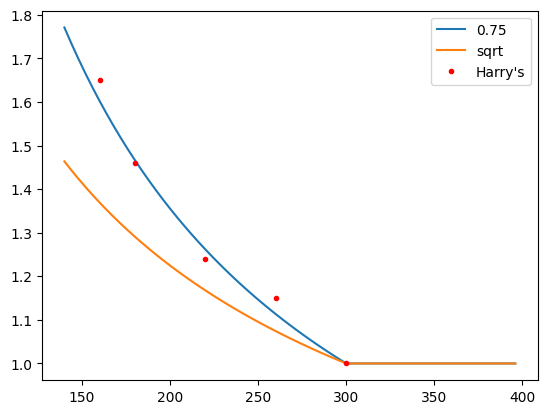

In [4]:
## roughly guess correction exponent for QE (copied data from harries paper, fit exponent by eye)
cutinWl = 300
# hand copied from harry's paper
wlenQY = [160, 180, 220, 260, 300]
yieldQY = [1.65, 1.46, 1.24, 1.15, 1.0]

nyield = lambda wlen, cutIn, power = 0.75 : np.where(wlen < cutinWl, (cutIn/wlen)**power, 1)
fpe = lambda pe, nyield: 1 - (1-pe)**nyield
shortX = np.arange(140, 400, 4)
nyield(shortX, cutinWl)
nyield(160, cutinWl)

plt.plot(shortX, nyield(shortX, cutinWl, 0.75), label = "0.75")
plt.plot(shortX, nyield(shortX, cutinWl, 0.5), label = "sqrt")
plt.plot(wlenQY, yieldQY, "r.", label = "Harry's")
plt.legend()
# plt.plot(shortX, fpe(0.9, nyield(shortX, cutinWl, 1)))

In [5]:
# plotting oxide absorption
# dh = OpticsData()
# plt.plot(hamX, 1e-6/dh.Oxide_absCoeff(hamX), label = "Oxide Absorption")

---
## Global fit, float all junction parameters
* float global: $X_{pn}$, $dw^*$, $dp^*$
* also float: $P_e$, $P_h$

data is an array of dicts, each dict is a dataset. Not using array of OneNuisanceDataSet

In [6]:
hamErrorFrac = 0.02
wlenCut = 170
dataMask = hamX > wlenCut
hamYerr = np.repeat(0.02, len(hamY))
data_Ham = [
    {"wlen":hamX[dataMask], "yVals":hamY[dataMask], "yErrs":hamYerr[dataMask], "theta1":0}
    ]

fixedPars_junction = { "FF":FF1, 'tOxide': ttGood, "Temperature":None, **fixedPars_Boring}
floatPars_junction = {'dp_star': 1.15, "Xpn":1330, "dw_star":12e3, "pe":0.9, "ph":0.3}


In [7]:
floatBounds_junction = {key:item for key, item in floatBounds_global_pickFrom.items() if key in floatPars_junction.keys()}

SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen, dataObj=data_Ham, dFixed=fixedPars_junction, dFloat=floatPars_junction,
                                   dBounds=floatBounds_junction, yNames=("yVals", "yErrs"), verbose=False)
x0, x0Name = SS.BuildX0(floatPars_junction, FF.PDE_allArgs_wlen)
x0Bounds = SS.BuildX0_bounds(floatBounds_junction, FF.PDE_allArgs_wlen)

guess = SS.GenericResiduals(x0=x0, dataObj=data_Ham, functionToFit=FF.PDE_allArgs_wlen, fixedArgs_dict=fixedPars_junction,
                    verbose=False, yNames=("yVals", "yErrs"))
print("guess:", guess)

fitResult_junction = iminuit.minimize(SS.GenericResiduals, x0=x0, bounds = x0Bounds, args=(fixedPars_junction, data_Ham, FF.PDE_allArgs_wlen), method='migrad')

# print(fitResult_junction)
resPdict_junction = SS.GetResDict(fitResult_junction, x0Name)
resDictErrors_junction = SS.GetResErrorDict(fitResult_junction, x0Name)

print(fitResult_junction.message)
print("score:", fitResult_junction.fun)
print("global resutl dict:\n", resPdict_junction)
print("errors\n",resDictErrors_junction)

guess: 111.10970194582684
Optimization terminated successfully.
score: 16.42767488505954
global resutl dict:
 {'dp_star': 0.8616, 'Xpn': 2672.027, 'dw_star': 11805.7872, 'pe': 0.8473, 'ph': 0.2619}
errors
 {'dp_star': 0.0858, 'Xpn': 391.5325, 'dw_star': 3682.2043, 'pe': 0.009, 'ph': 0.0943}


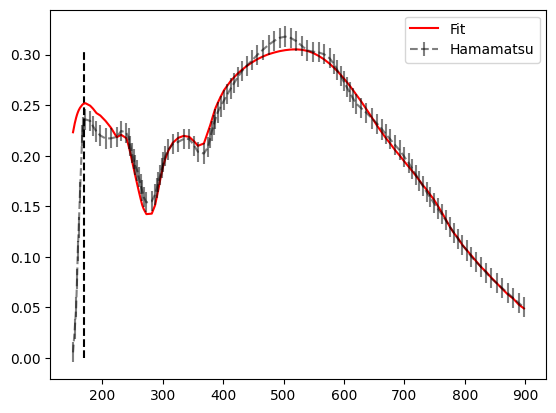

In [8]:
## plotting
# dh = OpticsData()
# print(dh.Si_absCoeff(160))

yFit_junction = FF.PDE_allArgs_wlen(hamX, theta1=0, **resPdict_junction, **fixedPars_junction)
# plt.plot(1/dh.Si_absCoeff(hamX), yFit_junction, label = "Fit", color = "red")
# plt.errorbar(1/dh.Si_absCoeff(hamX), hamY, hamYerr, alpha = 0.5, label = "Hamamatsu", color = "black", linestyle = "--")
# plt.xscale("log")
# plt.xlim(3, 100)
plt.vlines(wlenCut, 0, max(yFit_junction), color = "black", linestyle = "--")
plt.plot(hamX, yFit_junction, label = "Fit", color = "red")
plt.errorbar(hamX, hamY, hamYerr/2, alpha = 0.5, label = "Hamamatsu", color = "black", linestyle = "--")

# plt.xlim(120, 200)
plt.legend()
plt.show()

---
### Pe shape at different temps


In [9]:
## Loading in Harry's PE data
file_path_pe = os.path.join(VERA_DATA_PATH, "HPK_EHPAIR_183K.csv")
df_pe = pd.read_csv(file_path_pe, header=0)

# print(df_pe)
df_pe=df_pe[df_pe['Wavelength'] == 380]
# print(df_pe)

harryPe = df_pe['normalized rate'].values
harryVoltagePE = df_pe['Overvoltage'].values
harryPedict = {df_pe["Overvoltage"].values[i]: harryPe[i] for i in range(len(harryPe))}

print("---- Harry Pe values ----")
print(harryPedict)

# plt.figure(figsize=(4, 3))
# plt.plot(df_pe["Overvoltage"], harryPe, marker = "o")
# plt.show()

---- Harry Pe values ----
{1: 0.486306, 2: 0.733673, 3: 0.858569, 4: 0.925484, 5: 0.961845, 6: 0.981696, 7: 0.993065, 8: 0.997103, 9: 1.0}


{'dp_star': 0.8616, 'Xpn': 2672.027, 'dw_star': 11805.7872, 'pe': 0.8473, 'ph': 0.2619}


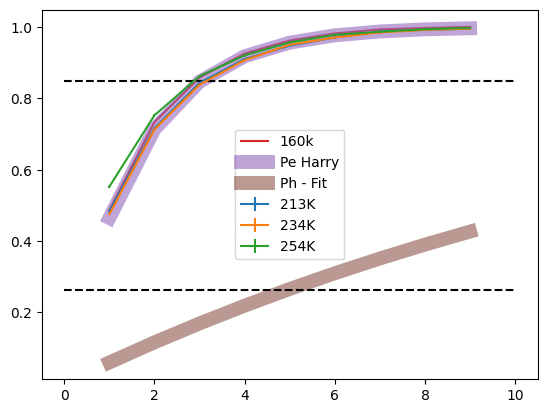

In [10]:
## more PE data from harry (different temps)
# Overvoltage values (in volts)

## 213K
overvoltage_213k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_213k = [0.483472, 0.716106, 0.843067, 0.909759, 0.947856, 0.970744, 0.986914, 0.991769, 0.995295]
pa_error_213k = [0.00141454, 0.00177954, 0.00201053, 0.00214232, 0.00222166, 0.00227794, 0.00232136, 0.002344, 0.00236474]
plt.errorbar(overvoltage_213k, pa_213k, pa_error_213k, label = "213K")

## 234K
overvoltage_234k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_234k = [0.475454, 0.713112, 0.838329, 0.906976, 0.95025, 0.970392, 0.984652, 0.991921, 0.995033]
pa_error_234k = [0.00221301, 0.00242933, 0.0026546, 0.00280772, 0.00292199, 0.00299275, 0.00305944, 0.00311978, 0.003172]
plt.errorbar(overvoltage_234k, pa_234k, pa_error_234k, label = "234K")

## -20
overvoltage_254k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_254k = [0.552663, 0.752471, 0.862244, 0.920471, 0.956795, 0.978047, 0.986519, 0.993679, 0.997341]
pa_error_254k = [0.00249031, 0.00291201, 0.0032007, 0.00339486, 0.00355269, 0.00367885, 0.00378663, 0.00389088, 0.00399673]
plt.errorbar(overvoltage_254k, pa_254k, pa_error_254k, label = "254K")

plt.plot(harryVoltagePE, harryPe, label="160k")

plt.plot(harryVoltagePE, ME.Pcar_parametrized(harryVoltagePE, Vc=1.6), linewidth = 10, alpha=0.6, label = "Pe Harry")

plt.plot(harryVoltagePE, ME.Pcar_parametrized(harryVoltagePE, Vc=vH_wlenFit), linewidth = 10, alpha=0.6, label = "Ph - Fit")

# plt.xlim(2, 5)
# plt.ylim(0.9, 1)
# plt.yscale("linear")
plt.hlines(resPdict_junction["pe"], 0, 10, color = "black", linestyle = "--")
plt.hlines(resPdict_junction["ph"], 0, 10, color = "black", linestyle = "--")
print(resPdict_junction)
plt.legend()
plt.show()

---
### Only floating junction (geometry) parameters.
fixed toxide, parametrized Pe, Ph from our data fits
float voltage, geometry

In [11]:
fixedPars_geo = {'tOxide': ttGood, "FF":FF1, "Ve":vE_wlenFit, "Vh":vH_wlenFit, "Ae":1.0, "Ah":1.0, "Temperature":None, **fixedPars_Boring}
floatPars_geo = {'dp_star': 1.15, "Xpn":1330, "dw_star":12e3, "voltage":4.0}
print(fixedPars_geo)
print(floatPars_geo)


{'tOxide': 16.8, 'FF': 0.6, 'Ve': 1.7648, 'Vh': 16.1748, 'Ae': 1.0, 'Ah': 1.0, 'Temperature': None, 'quantum': True, 'smoothSigma': None, 'dh': None, 'window': True}
{'dp_star': 1.15, 'Xpn': 1330, 'dw_star': 12000.0, 'voltage': 4.0}


In [12]:
floatBounds_geo = {key:item for key, item in floatBounds_global_pickFrom.items() if key in floatPars_geo.keys()}

SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized, dataObj=data_Ham, dFixed=fixedPars_geo, dFloat=floatPars_geo,
                                   dBounds=floatBounds_geo, yNames=("yVals", "yErrs"), verbose=False)
x0, x0Name = SS.BuildX0(floatPars_geo, FF.PDE_allArgs_wlen_parametrized)
x0Bounds = SS.BuildX0_bounds(floatBounds_geo, FF.PDE_allArgs_wlen_parametrized)

guess = SS.GenericResiduals(x0=x0, dataObj=data_Ham, functionToFit=FF.PDE_allArgs_wlen_parametrized, fixedArgs_dict=fixedPars_geo,
                    verbose=False, yNames=("yVals", "yErrs"))
print("guess:", guess)

fitResult_geo = iminuit.minimize(SS.GenericResiduals, x0=x0, bounds = x0Bounds, args=(fixedPars_geo, data_Ham, FF.PDE_allArgs_wlen_parametrized), method='migrad')

# print(fitResult_geo)
resPdict_geo = SS.GetResDict(fitResult_geo, x0Name)
resDictErrors_geo = SS.GetResErrorDict(fitResult_geo, x0Name)

print(fitResult_geo.message)
print("score:", fitResult_geo.fun)
print("global resutl dict:\n", resPdict_geo)
print("errors\n",resDictErrors_geo)


guess: 239.92454937294946
Optimization terminated successfully.
score: 16.853743851459456
global resutl dict:
 {'dp_star': 0.8489, 'Xpn': 2994.3552, 'dw_star': 15876.3262, 'voltage': 3.2915}
errors
 {'dp_star': 0.0846, 'Xpn': 153.2413, 'dw_star': 2386.1473, 'voltage': 0.0987}


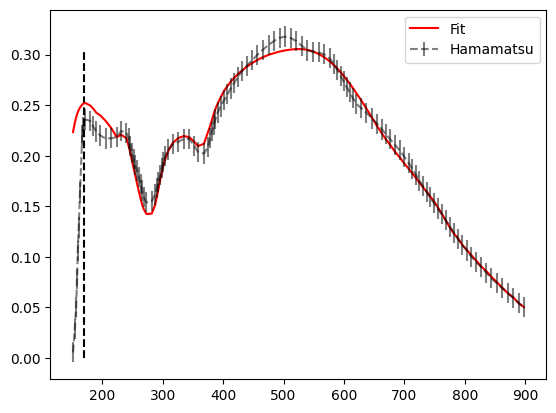

In [13]:
yFit = FF.PDE_allArgs_wlen_parametrized(hamX, theta1=0, **resPdict_geo, **fixedPars_geo)
plt.vlines(wlenCut, 0, max(yFit), color = "black", linestyle = "--")
plt.plot(hamX, yFit, label = "Fit", color = "red")
plt.errorbar(hamX, hamY, hamYerr/2, alpha = 0.5, label = "Hamamatsu", color = "black", linestyle = "--")

# plt.xlim(120, 200)
plt.legend()
plt.show()

---
### Floating voltage, toxide
Everything else informed from our data fits

In [14]:
fixedPars_vOxide = {**fitVal_dict, "FF":FF1, "Ae":1.0, "Ah":1.0, "Temperature":None, **fixedPars_Boring}
floatPars_vOxide = {'tOxide': ttGood, "voltage":4.0}

print(fixedPars_vOxide)
print(floatPars_vOxide)

{'dp_star': 1.407, 'Xpn': 2318.8184, 'dw_star': 13299.2962, 'Ve': 1.7648, 'Vh': 16.1748, 'FF': 0.6, 'Ae': 1.0, 'Ah': 1.0, 'Temperature': None, 'quantum': True, 'smoothSigma': None, 'dh': None, 'window': True}
{'tOxide': 16.8, 'voltage': 4.0}


In [15]:
floatBounds_vOxide = {key:item for key, item in floatBounds_global_pickFrom.items() if key in floatPars_vOxide.keys()}

SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized, dataObj=data_Ham, dFixed=fixedPars_vOxide, dFloat=floatPars_vOxide,
                                   dBounds=floatBounds_vOxide, yNames=("yVals", "yErrs"), verbose=False)
x0, x0Name = SS.BuildX0(floatPars_vOxide, FF.PDE_allArgs_wlen_parametrized)
x0Bounds = SS.BuildX0_bounds(floatBounds_vOxide, FF.PDE_allArgs_wlen_parametrized)

guess = SS.GenericResiduals(x0=x0, dataObj=data_Ham, functionToFit=FF.PDE_allArgs_wlen_parametrized, fixedArgs_dict=fixedPars_vOxide,
                    verbose=False, yNames=("yVals", "yErrs"))
print("guess:", guess)

fitResult_vOxide = iminuit.minimize(SS.GenericResiduals, x0=x0, bounds = x0Bounds, args=(fixedPars_vOxide, data_Ham, FF.PDE_allArgs_wlen_parametrized), method='migrad')

# print(fitResult_vOxide)
resPdict_vOxide = SS.GetResDict(fitResult_vOxide, x0Name)
resDictErrors_vOxide = SS.GetResErrorDict(fitResult_vOxide, x0Name)

print(fitResult_vOxide.message)
print("score:", fitResult_vOxide.fun)
print("global resutl dict:\n", resPdict_vOxide)
print("errors\n",resDictErrors_vOxide)


guess: 43.56216276782636
Optimization terminated successfully.
score: 38.910569589831304
global resutl dict:
 {'tOxide': 19.3061, 'voltage': 3.8049}
errors
 {'tOxide': 0.8345, 'voltage': 0.1006}


-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
0.16493361431346415


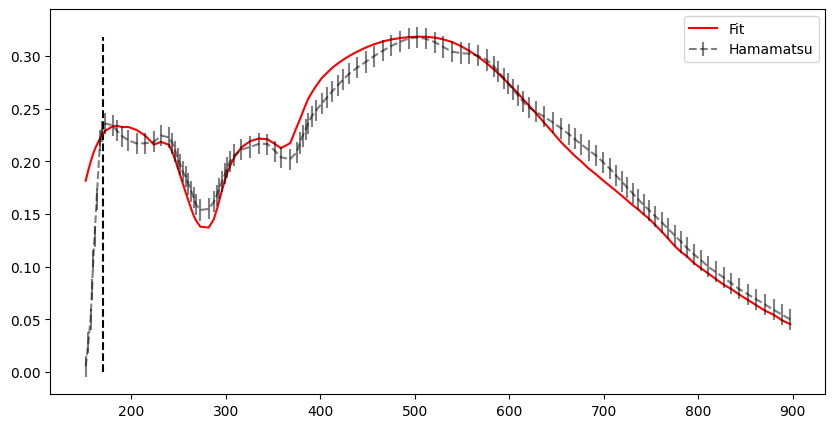

In [16]:
## plotting
fig = plt.figure(figsize=(10, 5))
dh = OpticsData()
print(dh.Si_absCoeff(160))

yFit = FF.PDE_allArgs_wlen_parametrized(hamX, theta1=0, **resPdict_vOxide, **fixedPars_vOxide)
plt.vlines(wlenCut, 0, max(yFit), color = "black", linestyle = "--")
plt.plot(hamX, yFit, label = "Fit", color = "red")
plt.errorbar(hamX, hamY, hamYerr/2, alpha = 0.5, label = "Hamamatsu", color = "black", linestyle = "--")

# plt.xlim(120, 200)
plt.legend()
plt.show()

---
### plotting all curves

In [17]:
file_path = os.path.join(VERA_DATA_PATH, "HPK_PDE_sept24.csv")
df = pd.read_csv(file_path, header=0)

if 'Harry' in file_path:
    print("Harry's data, cleaning up")
    # filter for angle = 0
    df = df[(df['Angle'] == 0)]
    df = df[(df['Wavelength'] > 300) & (df['Overvoltage'] > 0.5)]
# print(df.columns)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

data_angles = df['Angle'].unique()
data_voltages = df['Overvoltage'].unique()

print("Angles:", data_angles)
print("voltages:", data_voltages)

# take out one wavelength
# df = df[(df['Wavelength'] != 399.975) & ((df['Wavelength'] < 695) | (df['Wavelength'] > 705))]
pickV = 4
xVera = df[df['Overvoltage'] == pickV]['Wavelength']
yVera = df[df['Overvoltage'] == pickV]['PDE']
yErrVera = df[df['Overvoltage'] == pickV]['PDE_error']

     Wavelength  Angle  Overvoltage          Resp       PDE  PDE_error
387     789.983      0            8  1.487610e-13  0.114928   0.004171
388     799.950      0            8  1.338970e-13  0.103445   0.004119
389     810.007      0            8  1.252880e-13  0.096794   0.003343
390     820.008      0            8  1.147380e-13  0.088643   0.003168
391     829.983      0            8  1.056960e-13  0.081658   0.002833
--------------------------
Angles: [0]
voltages: [1 2 3 4 5 6 7 8]


temperature scaling not tested/validated below 300nm, be careful
{'FF': 0.6, 'tOxide': 16.8, 'dp_star': 1.407, 'Xpn': 2318.8184, 'dw_star': 13299.2962, 'Ve': 1.7648, 'Vh': 16.1748, 'quantum': True, 'smoothSigma': None, 'dh': None, 'window': True}


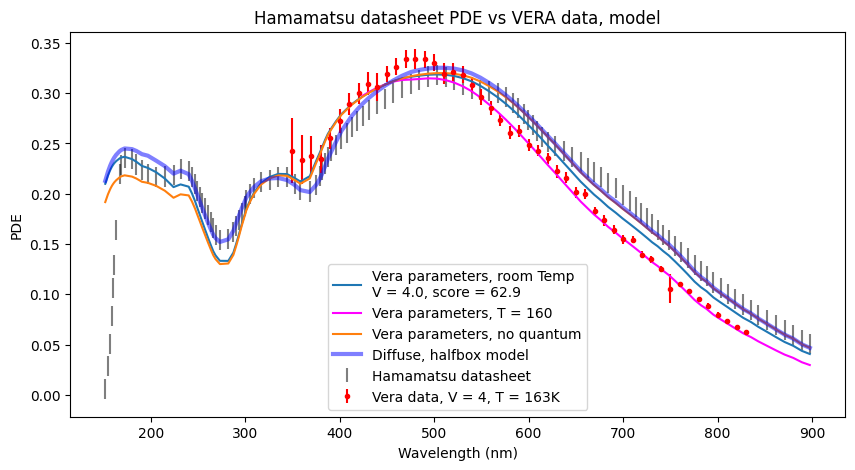

In [18]:
## plotting all 4 curves
from cycler import cycler
fig, ax1 = plt.subplots(1, 1, sharex=True, figsize = (10, 5))

colors = plt.cm.cool(np.linspace(0, 1, 4))
plt.rc('axes', prop_cycle=cycler('color', colors))

# hamamatsu datasheet
ax1.errorbar(hamX, hamY, hamYerr/2, alpha = 0.5, label = "Hamamatsu datasheet", linestyle = "None", color = "black")

# vera data
ax1.errorbar(xVera, yVera, yErrVera, label = f"Vera data, V = {pickV}, T = 163K", linestyle="None", marker = "o", markersize=3, color = "red")

# daaps curve
yFromData = FF.PDE_allArgs_wlen_parametrized(hamX, theta1=0, voltage = 4, Temperature = 250, **fullDaaps_dict)
print(fullDaaps_dict)
score = np.sum(((yFromData[dataMask] - hamY[dataMask])/hamYerr[dataMask])**2)
dataLabel = f"Vera parameters, room Temp\nV = 4.0, score = {score:.1f}"
ax1.plot(hamX, yFromData, label = dataLabel)

dict_modTemp = fullDaaps_dict.copy()
dict_modTemp["Temperature"] = 160
yVera_withTemp = FF.PDE_allArgs_wlen_parametrized(hamX[hamX > 420], theta1=0, voltage = 4, **dict_modTemp)
ax1.plot(hamX[hamX > 420], yVera_withTemp, color="magenta", label = "Vera parameters, T = 160")

# daps curve, no quantum
dict_noQuantum = fullDaaps_dict.copy()
dict_noQuantum["quantum"] = False
yFromData_noQuantum = FF.PDE_allArgs_wlen_parametrized(hamX, theta1=0, voltage = 4, **dict_noQuantum)
ax1.plot(hamX, yFromData_noQuantum, label = "Vera parameters, no quantum")

# floating everything in junction, voltage
yFit_junction = FF.PDE_allArgs_wlen(hamX, theta1=0, **resPdict_junction, **fixedPars_junction)
dpRatio = resPdict_junction["dp_star"]/fitVal_dict["dp_star"]
XpnRatio = resPdict_junction["Xpn"]/fitVal_dict["Xpn"]
dwRatio = resPdict_junction["dw_star"]/fitVal_dict["dw_star"]
lab_junction = f"Full datasheet fit, V = (3V, 4.5V) \ndp = {dpRatio:.2f}, Xpn = {XpnRatio:.2f}, dw = {dwRatio:.2f}" + f"\nscore = {fitResult_junction.fun:.1f}"
# plt.plot(hamX, yFit_junction, color="green", label = lab_junction)

# floating voltage, geometry
yFit_geo = FF.PDE_allArgs_wlen_parametrized(hamX, theta1=0, **resPdict_geo, **fixedPars_geo)
dpRatio = resPdict_geo["dp_star"]/fitVal_dict["dp_star"]
XpnRatio = resPdict_geo["Xpn"]/fitVal_dict["Xpn"]
dwRatio = resPdict_geo["dw_star"]/fitVal_dict["dw_star"]
lab_geo = f"Fit, V = {resPdict_geo['voltage']}, dp = {dpRatio:.2f}, Xpn = {XpnRatio:.2f}, dw = {dwRatio:.2f}"+ f"\nscore = {fitResult_geo.fun:.1f}"
# plt.plot(hamX, yFit_geo, color = "green", alpha = 0.5, label = lab_geo)

# floating oxide, voltage
yFit_vOxide = FF.PDE_allArgs_wlen_parametrized(hamX, theta1=0, **resPdict_vOxide, **fixedPars_vOxide)
lab_vox = f"Fit, tOxide = {resPdict_vOxide['tOxide']:.2f}, V = {resPdict_vOxide['voltage']:.2f}" + f"\nscore = {fitResult_vOxide.fun:.1f}"
# plt.plot(hamX, yFit_vOxide, color = "blue", alpha = 0.5, label = lab_vox)

# only floating voltage gives 4.02V, data apparently taken at 4V


diffuseDict = {'dp_star': 75.6316, 'Ve': 1.427, 'Pdiff': 0.802, 'Xpn': 2039.9945, 'dw_star': 11953.877, 'Vh': 13.5276}
fullDiffuseDict = {"FF": FF1, "tOxide": ttGood, **diffuseDict, **fixedPars_Boring}
# print(fullDiffuseDict["quantum"])
# fullDiffuseDict["quantum"] = True
yFit_diffuse = FF.PDE_allArgs_wlen_parametrized_halfBox(wlen=hamX, theta1 = 0, voltage = 4, **fullDiffuseDict)
plt.plot(hamX, yFit_diffuse, color = "blue", alpha = 0.5, linewidth = 3, label = "Diffuse, halfbox model")

plt.xlabel("Wavelength (nm)")
plt.ylabel("PDE")
plt.title("Hamamatsu datasheet PDE vs VERA data, model")
plt.legend()

## three fits

--- 
### Testing halfBox diffusion


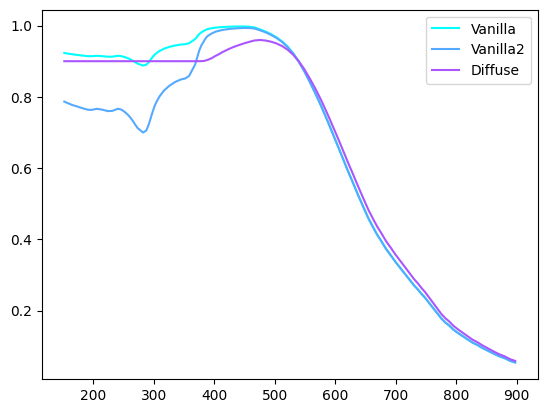

In [19]:
phTest = PhotonInfo(wlen = hamX)

Wp_vanilla = ME.Abs_layers(d_above=0.5, d_region = 2e3 - 165, mu=phTest.muSi, theta=0)
Wp_van2 = ME.Abs_layers(d_above=1.5, d_region = 2e3 - 165, mu=phTest.muSi, theta=0)
Wp_diff= ME.Abs_halfBox_Wp(d1=165, d2 = 2e3 - 165, mu = phTest.muSi, Pdiff = 0.9, theta=0)

# print in columns
# print(1/phTest.muSi)
# print(phTest.wlen)

plt.plot(hamX, Wp_vanilla, label = "Vanilla")
plt.plot(hamX, Wp_van2, label = "Vanilla2")
plt.plot(hamX, Wp_diff, label = "Diffuse")
plt.legend()

# plt.plot(hamX, 0.4*transTest, label="T - illegal", linestyle="--")
# plt.plot(hamX, 0.4*AbsTest, label="W - illegal", linestyle="--")

# plt.plot(hamX, (1 - np.exp(-4/1.7))*FF1*transTest*AbsTest, label="FULL - illegal", linestyle="-")

# plt.plot(hamX, hamY, label = "Hamamatsu", color = "black", linestyle = "--")


---
## plotting for argon

In [20]:
def n_Argon(wlen):
    x = wlen * 1e-3
    return (1+0.26+0.23/(1-(0.1066/x)**2)+0.0023/(1-(0.9083/x)**2))**.5

In [31]:
dict_static = {"quantum": True, "smoothSigma": None, "dh":None, "window":False}

## load in new json data
with open("fit_results.json", 'r') as file:
    json_fits = json.load(file)
    
default_global = json_fits["HPK_VUV4"]["default_global"]
dict_default_global = {key: value[0] for key, value in default_global["fit_parameters"].items()}
dict_default_global["tOxide"] = default_global["input_parameters"]["tOxide"][0]
dict_default_global["FF"] = default_global["input_parameters"]["FF"]

print("default global:\n", dict_default_global)

default global:
 {'dp_star': 1.02, 'Xpn': 2342, 'dw_star': 13574, 'Ve': 1.789, 'Vh': 16.62, 'tOxide': 16.84, 'FF': 0.6}


temperature scaling not tested/validated below 300nm, be careful
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-150K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-293K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PD

<__array_function__ internals>:200: ComplexWarning: Casting complex values to real discards the imaginary part
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


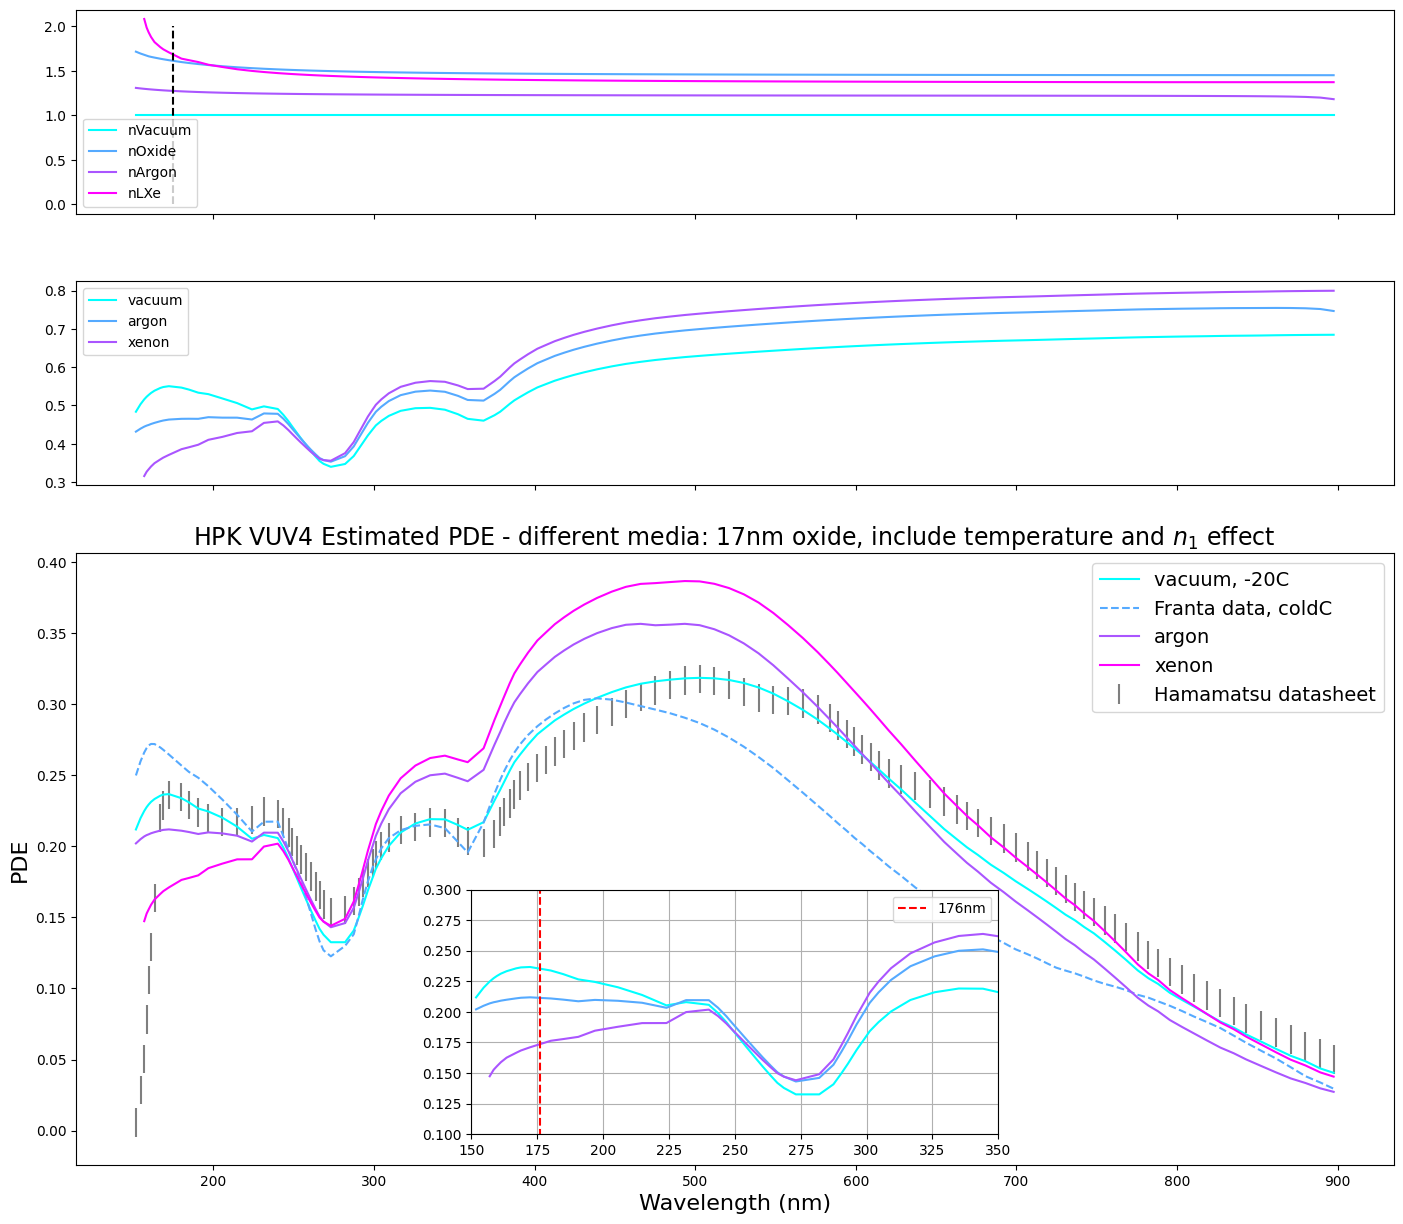

In [24]:
## plotting all 4 curves
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize = (17, 15), height_ratios=[1, 1, 3])
tOx_test = 50

colors = plt.cm.cool(np.linspace(0, 1, 4))
plt.rc('axes', prop_cycle=cycler('color', colors))


# hamamatsu datasheet
ax3.errorbar(hamX, hamY, hamYerr/2, alpha = 0.5, label = "Hamamatsu datasheet", linestyle = "None", color = "black")
# hamX = hamX[hamX < 130]

# daaps curve (mimic datasheet)
photon1 = PhotonInfo(wlen = hamX, mediumStr = "vacuum", materialTemp=250)
cd = fullDaaps_dict.copy()
cd.pop('smoothSigma')
cd.pop('dh')

# plotting many dh curves
dhFranta = ODL.OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
dhFranta_warm = ODL.OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-293K.txt"))
dhDefault = ODL.OpticsData()

# cd['tOxide'] = tOx_test

yFromData = FF.PDE_allArgs_wlen_parametrized_BADWRAPPER(photon1, voltage = 4, **cd)
print(fullDaaps_dict)

yFromData_Franta = FF.PDE_allArgs_wlen_parametrized(wlen = hamX, theta1=0, voltage = 4, **cd, dh=dhFranta)

ax1.plot(hamX, np.full_like(hamX, photon1.nVacuum), label = "nVacuum")
ax1.plot(hamX, photon1.nOxide, label = "nOxide")
ax2.plot(hamX, photon1.Wave_TotalTransmission(cd["tOxide"]), label = "vacuum")
ax3.plot(hamX, yFromData, label = "vacuum, -20C")

ax3.plot(hamX, yFromData_Franta, label = "Franta data, coldC", linestyle = "--")

# argon curve
argonN = n_Argon(hamX)
photon2 = PhotonInfo(wlen = hamX, mediumStr = "vacuum", materialTemp=90)
photon2.nVacuum = argonN
photon2.BuildThetas()
photon2.BuildPureRT()
yArgon = FF.PDE_allArgs_wlen_parametrized_BADWRAPPER(photon2, voltage = 4, **cd)

ax1.plot(hamX, argonN, label = "nArgon")
ax2.plot(hamX, photon2.Wave_TotalTransmission(cd["tOxide"]), label = "argon")
ax3.plot(hamX, yArgon, label = "argon")

# xenon curve
photon3 = PhotonInfo(wlen = hamX, mediumStr = "LXe", materialTemp=165)
yXenon = FF.PDE_allArgs_wlen_parametrized_BADWRAPPER(photon3, voltage = 4, **cd)
maxWlen_xenon = np.argmax(photon3.nVacuum) + 1

ax1.plot(hamX[maxWlen_xenon:], photon3.nVacuum[maxWlen_xenon:], label = "nLXe")
ax2.plot(hamX[maxWlen_xenon:], photon3.Wave_TotalTransmission(cd["tOxide"])[maxWlen_xenon:], label = "xenon")
ax3.plot(hamX[maxWlen_xenon:], yXenon[maxWlen_xenon:], label = "xenon")


ax1.vlines(175, 0, 2, color = "black", linestyle = "--")

ax1.legend()
ax2.legend()
ax3.legend()

# ax3.set_xlim(150, 250)
## ratio at 176nm
closestTo176 = np.argmin(np.abs(hamX - 176))
print("ratios at 176nm:", yXenon[closestTo176]/yArgon[closestTo176])

## adding inset graph
axins = ax3.inset_axes([0.3, 0.05, 0.4, 0.4])
axins.plot(hamX, yFromData)
axins.plot(hamX, yArgon)
axins.plot(hamX[maxWlen_xenon:], yXenon[maxWlen_xenon:])
axins.vlines(176, 0, .4, color = "red", linestyle = "--", label = "176nm")
axins.set_xlim(150, 350)
axins.set_ylim(0.1, 0.3)
axins.legend()
axins.grid()

# ax3.grid()

plt.xlabel("Wavelength (nm)", fontsize = 16)
plt.ylabel("PDE", fontsize = 16)
plt.title(r"HPK VUV4 Estimated PDE - different media: 17nm oxide, include temperature and $n_1$ effect", fontsize = 17)
plt.legend(fontsize = 14)

## three fits